# Restricted Boltzmann Machines

### Ising to Generalized Hopfield

Consider the pairwise Ising model:

$$
E(\mathbf v)=-\sum_i a_iv_i-\frac12\sum_{ij}v_iJ_{ij}v_j.
$$

Since the interaction matrix is symmetric, eigendecompose it and discard the **zero eigenmodes**:

$$
\mathbf J=\mathbf U\boldsymbol\Lambda\mathbf U^T
=\sum_\mu\lambda_\mu\mathbf u_\mu\mathbf u_\mu^T
=\sum_\mu\mathbf w_\mu\mathbf w_\mu^T
=\mathbf W\mathbf W^T,
$$

where

$$
\mathbf w_\mu=\sqrt{\lambda_\mu}\mathbf u_\mu.
$$

Define the overlap with collective mode $\mu$:

$$
m_\mu=\mathbf w_\mu^T\mathbf v=\sum_iW_{i\mu}v_i.
$$

Then

$$
\boxed{
E_{\mathrm{Hop}}(\mathbf v)
=-\sum_i a_iv_i-\frac12\sum_\mu m_\mu^2.
}
$$

We have rewritten pairwise interactions as squared overlaps with collective patterns, without changing the model.

### Gaussian Hidden Variables: Hubbard–Stratonovich Transformation

Start from the Boltzmann distribution:

$$
P(\mathbf v)=\frac1Z
e^{\sum_i a_iv_i}
\prod_\mu e^{m_\mu^2/2}.
$$

Introduce one continuous Gaussian hidden variable per collective mode using

$$
e^{m_\mu^2/2}
=\frac1{\sqrt{2\pi}}
\int_{-\infty}^{\infty}dh_\mu\,
e^{-h_\mu^2/2+h_\mu m_\mu}.
$$

**Proof:**

$$
-\frac12h_\mu^2+h_\mu m_\mu
=-\frac12(h_\mu-m_\mu)^2+\frac12m_\mu^2.
$$

Hence

$$
\begin{aligned}
\int dh_\mu\,e^{-h_\mu^2/2+h_\mu m_\mu}
&=e^{m_\mu^2/2}
\int dh_\mu\,e^{-(h_\mu-m_\mu)^2/2}\\
&=\sqrt{2\pi}\,e^{m_\mu^2/2}.
\end{aligned}
$$

Apply this identity to every mode:

$$
P(\mathbf v)=\frac1{Z(2\pi)^{M/2}}
\int d^M\mathbf h\,
e^{\sum_i a_iv_i-\frac12\sum_\mu h_\mu^2+\sum_\mu h_\mu m_\mu}.
$$

Substituting the overlaps gives the joint energy:

$$
\boxed{
E(\mathbf v,\mathbf h)
=-\mathbf a^T\mathbf v
+\frac12\mathbf h^T\mathbf h
-\mathbf v^T\mathbf W\mathbf h.
}
$$

**The quadratic visible-visible interactions have disappeared.** They are replaced by linear interactions mediated by stochastic auxiliary fields.

For a fixed visible configuration:

$$
\boxed{
h_\mu|\mathbf v\sim\mathcal N(m_\mu,1).
}
$$

Thus, the hidden field fluctuates around the corresponding collective overlap.

### Generalization: Bernoulli RBM

Keep the same bipartite interaction structure, but replace Gaussian hidden variables with Bernoulli units:

$$
h_\mu\in\{0,1\}.
$$

Introduce hidden biases and define the new joint energy:

$$
\boxed{
E(\mathbf v,\mathbf h)
=-\mathbf a^T\mathbf v-\mathbf b^T\mathbf h-\mathbf v^T\mathbf W\mathbf h.
}
$$

Marginalize over the hidden variables:

$$
\begin{aligned}
P(\mathbf v)
&\propto e^{\mathbf a^T\mathbf v}
\sum_{\mathbf h}
e^{\sum_\mu h_\mu(b_\mu+m_\mu)}\\
&=e^{\mathbf a^T\mathbf v}
\prod_\mu\sum_{h_\mu=0}^1e^{h_\mu(b_\mu+m_\mu)}\\
&=e^{\mathbf a^T\mathbf v}
\prod_\mu(1+e^{b_\mu+m_\mu}).
\end{aligned}
$$

Taking the negative logarithm gives the effective visible energy:

$$
\boxed{
E_{\mathrm{eff}}(\mathbf v)
=-\mathbf a^T\mathbf v
-\sum_\mu\log(1+e^{b_\mu+\mathbf w_\mu^T\mathbf v}).
}
$$

**Unlike the Gaussian transformation, this is generally a new visible distribution, not an exact reconstruction of the original pairwise Ising model.**

### Why Bernoulli Units Generate Higher-Order Interactions

For one hidden mode, define

$$
F(m)=\log(1+e^{b+m}).
$$

Taylor-expand around zero overlap:

$$
F(m)=F(0)+F'(0)m+\frac{F''(0)}2m^2
+\frac{F'''(0)}6m^3+\cdots.
$$

Since

$$
m=\sum_iW_iv_i,
$$

we obtain

$$
m^2=\sum_{ij}W_iW_jv_iv_j,
$$

$$
m^3=\sum_{ijk}W_iW_jW_kv_iv_jv_k,
$$

$$
m^4=\sum_{ijkl}W_iW_jW_kW_lv_iv_jv_kv_l.
$$

Thus, marginalization can generate effective pairwise, three-body, four-body, and higher-order interactions.

The contrast is:

$$
\boxed{
\begin{aligned}
\text{Gaussian:}\quad &F(m)=\frac12m^2,\\
\text{Bernoulli:}\quad &F(m)=\log(1+e^{b+m}).
\end{aligned}
}
$$

The Gaussian contribution is strictly quadratic; the Bernoulli contribution is nonlinear and generally contains higher orders.

### Size of Weight Matrix
For Gaussian hidden variables, arbitrary numbers of hidden units still produce only quadratic interactions:

$$
\mathbf J=\mathbf W\mathbf W^T,\qquad
\operatorname{rank}(\mathbf J)\leq N
$$

However, Bernoulli hidden variables, each additional column of $\mathbf{W}$ contributes another independently learned nonlinear function. Increasing the hidden-layer size can therefore capture more complex collective features and many-body interactions, rather than merely adding redundant quadratic modes.

### Remarks

These calculations make clear the underlying reason for the incredible representational power of RBMs with a Bernoulli
hidden layer. Each hidden unit can encode interactions of arbitrarily high order. By combining many different hidden units,
we can encode very complex interactions at all orders. Moreover, we can learn which order of correlations/interactions
are important directly from the data instead of having to specify them ahead of time as we did in the MaxEnt models.
This highlights the power of generative models with even the simplest interactions between visible and latent variables
to encode, learn, and represent complex correlations present in the data. (Mehta 97)

### Maximum Likelihood Estimation for RBMs

Given $K$ observed visible configurations, maximize the average log-likelihood:

$$
\mathcal L(\boldsymbol\theta)
=\frac1K\sum_{n=1}^{K}\log P_{\boldsymbol\theta}(\mathbf v^{(n)}),
$$

where $\boldsymbol\theta=\{\mathbf W,\mathbf a,\mathbf b\}$.

Recall the RBM energy and marginal distribution:

$$
E(\mathbf v,\mathbf h)
=-\mathbf a^T\mathbf v-\mathbf b^T\mathbf h-\mathbf v^T\mathbf W\mathbf h,
$$

$$
P(\mathbf v)=\frac{\sum_{\mathbf h}e^{-E(\mathbf v,\mathbf h)}}{Z},
\qquad
Z=\sum_{\mathbf v,\mathbf h}e^{-E(\mathbf v,\mathbf h)}.
$$

### Derivation for one weight $W_{i\mu}$

For one observed configuration $\mathbf v$:

$$
\log P(\mathbf v)
=\log\sum_{\mathbf h}e^{-E(\mathbf v,\mathbf h)}-\log Z.
$$

Differentiate with respect to $W_{i\mu}$, noting that

$$
\frac{\partial E}{\partial W_{i\mu}}=-v_ih_\mu.
$$

**Positive phase:**

$$
\begin{aligned}
\frac{\partial}{\partial W_{i\mu}}
\log\sum_{\mathbf h}e^{-E}
&=\frac{\sum_{\mathbf h}v_ih_\mu e^{-E}}
{\sum_{\mathbf h}e^{-E}}\\
&=\sum_{\mathbf h}v_ih_\mu
\underbrace{\frac{e^{-E(\mathbf v,\mathbf h)}}
{\sum_{\mathbf h'}e^{-E(\mathbf v,\mathbf h')}}}_{P(\mathbf h|\mathbf v)}\\
&=\mathbb E_{\mathbf h|\mathbf v}[v_ih_\mu].
\end{aligned}
$$

**Why does the conditional probability appear?**

During differentiation, the observed $\mathbf v$ is fixed, while we sum over all possible hidden configurations. The ratio is

$$
\frac{e^{-E(\mathbf v,\mathbf h)}}
{\sum_{\mathbf h'}e^{-E(\mathbf v,\mathbf h')}}
=
\frac{P(\mathbf v,\mathbf h)}{P(\mathbf v)}
=
P(\mathbf h|\mathbf v).
$$

Thus, the derivative is the expectation of $v_ih_\mu$ over hidden variables **conditioned on the observed visible configuration**.

However, this is not yet the data expectation: it is the conditional expectation for **one sample**.

Average it over all $K$ observed configurations:

$$
\begin{aligned}
\frac1K\sum_{n=1}^K
\mathbb E_{\mathbf h|\mathbf v^{(n)}}[v_i^{(n)}h_\mu]
&=
\frac1K\sum_{n=1}^K
\sum_{\mathbf h}
v_i^{(n)}h_\mu P(\mathbf h|\mathbf v^{(n)})\\
&\equiv
\boxed{\langle v_ih_\mu\rangle_{\mathrm{data}}}.
\end{aligned}
$$

The subscript *data* therefore means:

1. Average over observed visible configurations using the empirical data distribution.
2. For each visible configuration, average over unobserved hidden variables using the model's conditional distribution.

The hidden variables themselves are **not measured in the dataset**.

**Negative phase:**

Now differentiate the partition function:

$$
\begin{aligned}
\frac{\partial\log Z}{\partial W_{i\mu}}
&=\frac1Z\sum_{\mathbf v,\mathbf h}v_ih_\mu e^{-E(\mathbf v,\mathbf h)}\\
&=\sum_{\mathbf v,\mathbf h}
v_ih_\mu P(\mathbf v,\mathbf h)\\
&=\boxed{\langle v_ih_\mu\rangle_{\mathrm{model}}}.
\end{aligned}
$$

Here neither layer is fixed: the expectation is taken over the **full joint model distribution**.

### Final MLE gradients

Combining both phases:

$$
\boxed{
\frac{\partial\mathcal L}{\partial W_{i\mu}}
=
\underbrace{\langle v_ih_\mu\rangle_{\mathrm{data}}}_{\text{observed }\mathbf v,\ \text{inferred }\mathbf h}
-
\underbrace{\langle v_ih_\mu\rangle_{\mathrm{model}}}_{\text{both layers sampled from model}}.
}
$$

The same derivation for the biases yields

$$
\boxed{
\begin{aligned}
\frac{\partial\mathcal L}{\partial a_i}
&=\langle v_i\rangle_{\mathrm{data}}
-\langle v_i\rangle_{\mathrm{model}},\\[2mm]
\frac{\partial\mathcal L}{\partial b_\mu}
&=\langle h_\mu\rangle_{\mathrm{data}}
-\langle h_\mu\rangle_{\mathrm{model}}.
\end{aligned}
}
$$

### Interpretation

As in pairwise MaxEnt, MLE adjusts the model so that its expected statistics agree with the statistics supported by the data.

The difference is that the RBM sufficient statistics include latent variables:

$$
\boxed{
\text{MLE gradient}
=
\text{data-conditioned expectation}
-
\text{model expectation}.
}
$$

The positive phase uses observed visible configurations and inferred hidden activations; the negative phase uses the model's own joint distribution.

At an interior MLE stationary point, these two expectations match for every parameter. This is the RBM analogue of the moment-matching conditions in pairwise MaxEnt.

### Calculating the Positive Phase: Observed Statistics

Recall the positive-phase expectation in the MLE gradient:

$$
\langle v_i h_\mu\rangle_{\mathrm{data}}.
$$

**Problem:** Our dataset contains only visible configurations:

$$
\mathcal D=\{\mathbf v^{(1)},\ldots,\mathbf v^{(K)}\}.
$$

The hidden variables are never observed. Therefore, we cannot directly measure their correlations with the visible spins.

**Solution:** For each observed configuration, infer the expected hidden activation using the current RBM parameters.

#### Deriving the conditional hidden distribution

Recall the RBM energy:

$$
E(\mathbf v,\mathbf h)
=-\mathbf a^T\mathbf v-\mathbf b^T\mathbf h-\mathbf v^T\mathbf W\mathbf h.
$$

Conditioning on a fixed visible configuration:

$$
\begin{aligned}
P(\mathbf h|\mathbf v)
&=\frac{P(\mathbf v,\mathbf h)}{P(\mathbf v)}\\
&=\frac{e^{-E(\mathbf v,\mathbf h)}}{\sum_{\mathbf h'}e^{-E(\mathbf v,\mathbf h')}}\\
&=\frac{\exp\left[\sum_\mu h_\mu(b_\mu+\sum_iW_{i\mu}v_i)\right]}
{\sum_{\mathbf h'}\exp\left[\sum_\mu h'_\mu(b_\mu+\sum_iW_{i\mu}v_i)\right]}.
\end{aligned}
$$

The visible bias term cancels because $\mathbf v$ is fixed.

Since hidden units have no mutual interactions, the distribution factorizes:

$$
\boxed{
P(\mathbf h|\mathbf v)=\prod_\mu P(h_\mu|\mathbf v).
}
$$

For one hidden unit, define

$$
z_\mu=b_\mu+\sum_iW_{i\mu}v_i.
$$

Since $h_\mu\in\{0,1\}$,

$$
\begin{aligned}
P(h_\mu=1|\mathbf v)
&=\frac{e^{z_\mu}}{e^{0}+e^{z_\mu}}\\
&=\frac1{1+e^{-z_\mu}}.
\end{aligned}
$$

Therefore,

$$
\boxed{
P(h_\mu=1|\mathbf v)
=\sigma\left(b_\mu+\sum_iW_{i\mu}v_i\right).
}
$$

#### Calculating the positive-phase expectation

Since $h_\mu\in\{0,1\}$, its conditional expectation is

$$
\begin{aligned}
\mathbb E_\theta[h_\mu|\mathbf v]
&=0\cdot P(h_\mu=0|\mathbf v)
+1\cdot P(h_\mu=1|\mathbf v)\\
&=\sigma\left(b_\mu+\sum_jW_{j\mu}v_j\right).
\end{aligned}
$$

For one observed configuration, $v_i$ is fixed:

$$
\mathbb E_\theta[v_ih_\mu|\mathbf v]
=v_i\,\sigma\left(b_\mu+\sum_jW_{j\mu}v_j\right).
$$

Finally, average over all $K$ observed configurations:

$$
\boxed{
\langle v_ih_\mu\rangle_{\mathrm{data}}
=
\frac1K\sum_{n=1}^K
v_i^{(n)}
\sigma\left(
b_\mu+\sum_jW_{j\mu}v_j^{(n)}
\right).
}
$$

#### Interpretation

The positive phase combines two distributions:

- **Visible variables:** Empirical distribution $P_{\mathrm{data}}(\mathbf v)$.
- **Hidden variables:** Model-implied conditional distribution $P_\theta(\mathbf h|\mathbf v)$.

More precisely, the expectation is taken over

$$
\boxed{
Q_\theta(\mathbf v,\mathbf h)
=
P_{\mathrm{data}}(\mathbf v)
P_\theta(\mathbf h|\mathbf v).
}
$$

Thus, $\langle v_ih_\mu\rangle_{\mathrm{data}}$ is shorthand for a **data-conditioned model expectation**, not a directly measured visible-hidden correlation.

The positive-phase bias expectations follow immediately:

$$
\boxed{
\begin{aligned}
\langle v_i\rangle_{\mathrm{data}}
&=\frac1K\sum_n v_i^{(n)},\\[2mm]
\langle h_\mu\rangle_{\mathrm{data}}
&=\frac1K\sum_n
\sigma\left(b_\mu+\sum_jW_{j\mu}v_j^{(n)}\right).
\end{aligned}
}
$$

**Computational consequence:** The positive phase can be evaluated directly from observed configurations and the current parameters, without sampling hidden variables or calculating the partition function.

### Calculating Negative Phase: Gibbs Sampling and Contrastive Divergence

Recall the Bernoulli RBM energy:

$$
E(\mathbf v,\mathbf h)
=-\mathbf a^T\mathbf v-\mathbf b^T\mathbf h-\mathbf v^T\mathbf W\mathbf h.
$$

The **positive phase** fixes observed $\mathbf v$ and calculates hidden expectations using $P(\mathbf h|\mathbf v)$.

The **negative phase** requires expectations under the joint model distribution $P(\mathbf v,\mathbf h)$. We approximate these by generating samples through Gibbs sampling.

#### Conditional Independence of Both Layers

We already derived:

$$
\boxed{
P(\mathbf h|\mathbf v)=\prod_\mu P(h_\mu|\mathbf v),
\qquad
P(h_\mu=1|\mathbf v)
=\sigma\left(b_\mu+\sum_iW_{i\mu}v_i\right).
}
$$

The same reasoning applies in the reverse direction. Fix $\mathbf h$:

$$
\begin{aligned}
P(\mathbf v|\mathbf h)
&=\frac{e^{-E(\mathbf v,\mathbf h)}}{\sum_{\mathbf v'}e^{-E(\mathbf v',\mathbf h)}}\\
&=\frac{\exp\left[\sum_i v_i(a_i+\sum_\mu W_{i\mu}h_\mu)\right]}
{\sum_{\mathbf v'}\exp\left[\sum_i v_i'(a_i+\sum_\mu W_{i\mu}h_\mu)\right]}.
\end{aligned}
$$

Define the effective visible field:

$$
z_i=a_i+\sum_\mu W_{i\mu}h_\mu.
$$

Since visible units have no mutual interactions, the denominator factorizes:

$$
\begin{aligned}
P(\mathbf v|\mathbf h)
&=\frac{\prod_i e^{v_iz_i}}{\prod_i(1+e^{z_i})}\\
&=\prod_i\frac{e^{v_iz_i}}{1+e^{z_i}}.
\end{aligned}
$$

Therefore, for Bernoulli visible units $v_i\in\{0,1\}$,

$$
\boxed{
P(\mathbf v|\mathbf h)=\prod_iP(v_i|\mathbf h),
\qquad
P(v_i=1|\mathbf h)
=\sigma\left(a_i+\sum_\mu W_{i\mu}h_\mu\right).
}
$$

**Concept:** Fixing either layer removes all statistical dependence *within* the other layer. Every unit can be sampled independently and simultaneously.

*Note:* For Ising visibles $v_i\in\{-1,+1\}$, the corresponding probability is $P(v_i=+1|\mathbf h)=\sigma(2z_i)$.

#### Block Gibbs Sampling

We alternate between these two conditional distributions:

$$
\boxed{
\mathbf v^{(0)}
\xrightarrow{P(\mathbf h|\mathbf v)}
\mathbf h^{(1)}
\xrightarrow{P(\mathbf v|\mathbf h)}
\mathbf v^{(1)}
\xrightarrow{P(\mathbf h|\mathbf v)}
\mathbf h^{(2)}
\longrightarrow\cdots
}
$$

At each iteration:

1. Fix $\mathbf v^{(t)}$, calculate hidden activation probabilities, and sample $\mathbf h^{(t+1)}$.
2. Fix $\mathbf h^{(t+1)}$, calculate visible activation probabilities, and sample $\mathbf v^{(t+1)}$.
3. Repeat until the chain approximately reaches the model equilibrium distribution.

**Important distinction from the positive phase:** We do not keep the original visible configuration fixed. Both layers fluctuate, allowing the Markov chain to explore configurations generated by the model itself.

Each step is cheap because the conditional distributions factorize. After sufficient equilibration, samples can estimate the negative-phase expectation:

$$
\boxed{
\langle v_ih_\mu\rangle_{\mathrm{model}}
\approx
\frac1S\sum_{s=1}^S
v_i^{(s)}h_\mu^{(s)}.
}
$$

Here the samples are collected from equilibrated chains (the *fantasy particles*). Successive samples may remain correlated, so sufficient mixing is important.

#### Toy Example: One Gibbs Iteration

Consider two Bernoulli visible units and one hidden unit, with

$$
\mathbf W=\begin{pmatrix}1\\1\end{pmatrix},
\qquad
\mathbf a=\mathbf0,\qquad b=0.
$$

Start with the random configuration:

$$
\mathbf v^{(0)}=(1,0)^T.
$$

**Visible → Hidden:**

$$
P(h=1|\mathbf v^{(0)})
=\sigma(1)=0.731.
$$

Suppose our random draw gives $h^{(1)}=1$.

**Hidden → Visible:**

$$
P(v_1=1|h^{(1)})=P(v_2=1|h^{(1)})
=\sigma(1)=0.731.
$$

Draw each visible spin independently. Suppose we obtain

$$
\mathbf v^{(1)}=(1,1)^T.
$$

We have now generated a new visible configuration. The next hidden update gives

$$
P(h=1|\mathbf v^{(1)})=\sigma(2)=0.881.
$$

Continuing these stochastic updates allows the chain to move through the model's configuration space.

#### Contrastive Divergence (CD) and Persistent CD

Full Gibbs sampling can require many iterations to reach equilibrium, especially when the model contains separated probability modes.

**Contrastive Divergence (CD-\(k\))** approximates the negative phase using only $k$ Gibbs iterations, starting from observed data:

$$
\mathbf v_{\mathrm{data}}
\rightarrow\mathbf h^{(1)}
\rightarrow\mathbf v^{(1)}
\rightarrow\cdots
\rightarrow\mathbf v^{(k)}.
$$

Why start from observed data? Because the data are already in regions we want the model to assign high probability to. CD assumes that taking a few steps away from these configurations can provide a useful approximate learning signal.

For CD-1, we stop after one visible reconstruction. This reduces computational cost but generally introduces bias because the chain has not equilibrated.

**Persistent Contrastive Divergence (PCD)** instead retains the model-generated samples across parameter updates:

$$
\boxed{
\text{previous fantasy particles}
\rightarrow
\text{additional Gibbs iterations}
\rightarrow
\text{new fantasy particles}.
}
$$

Unlike CD, PCD does not continually restart near the observed data, allowing longer exploration of the model distribution. For the first step, PCD also starts from the random initialization (like regular Block Gibbs) and not the observed data.

**Summary:** The positive phase performs a single conditional inference with observed visibles held fixed. The negative phase repeatedly alternates the same conditional operations to sample from the model's own distribution. CD and PCD approximate this second process with shorter computational effort.

### Dataset: MNIST
We will use the 21x21 digit image dataset to train our generative model

In [16]:
import torch
from torchvision import datasets, transforms
from torch.utils.data import DataLoader

torch.manual_seed(42)
device = torch.device("mps") if torch.backends.mps.is_available() else torch.device("cpu")

transform = transforms.ToTensor()

train_data = datasets.MNIST(
    root="./data",
    train=True,
    download=True,
    transform=transform
)

test_data = datasets.MNIST(
    root="./data",
    train=False,
    download=True,
    transform=transform
)

In [17]:
image, label = train_data[0]
print(image.shape, image.dtype, label)
print(image.flatten().min(),image.flatten().max())
print(train_data.data[0])

torch.Size([1, 28, 28]) torch.float32 5
tensor(0.) tensor(1.)
tensor([[  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,
           0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0],
        [  0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   0,   3,  18,
          18,  18, 126, 136, 175,  26, 166, 255, 247, 127,   0, 

In [18]:
X_train = train_data.data.float() / 255.0
X_test = test_data.data.float() / 255.0

# Binarize and flatten
X_train = (X_train > 0.5).float().reshape(-1, 784)
X_test = (X_test > 0.5).float().reshape(-1, 784)

print(X_train.shape)  # torch.Size([60000, 784])
print(X_test.shape)   # torch.Size([10000, 784])

torch.Size([60000, 784])
torch.Size([10000, 784])


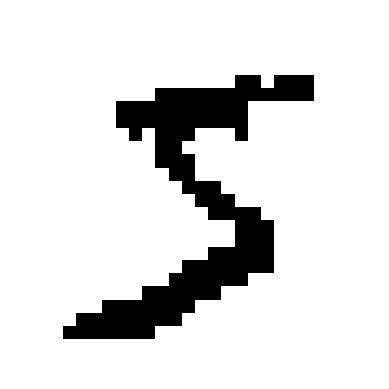

In [19]:
import matplotlib.pyplot as plt

plt.imshow(1 - X_train[0].reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()

### Initialization
We will initialize the model weights $W_{i \mu}$ from a gaussian, and set the visible & hidden biases to zero.

We will choose $W$ to be size $784 \times 64$, that is, 64 collective modes associated to hidden variables.

In [20]:
N = 784   # Visible units (28 × 28)
M = 64    # Hidden units

W = 0.01 * torch.randn(N, M, device=device)
a = torch.zeros(N, device=device)
b = torch.zeros(M, device=device)

def rbm_energy(v, h, W, b_v, b_h):
    """Joint energy for one state or a batch of paired visible/hidden states."""
    return -(v * b_v).sum(dim=-1) - (h * b_h).sum(dim=-1) - ((v @ W) * h).sum(dim=-1)


In [21]:
def sigmoid(x):
    return torch.sigmoid(x)

def hidden_probabilities(v, W, b_h):
    """P(h=1 | v): accepts [N] or [batch, N], returns [M] or [batch, M]."""
    return sigmoid(v @ W + b_h)

def visible_probabilities(h, W, b_v):
    """P(v=1 | h): accepts [M] or [batch, M], returns [N] or [batch, N]."""
    return sigmoid(h @ W.T + b_v)


### Initial Results

Lets sample from our initial model. To do this we will start from a random $\mathbf{v}$ and then apply MCMC Block Gibbs Sampling

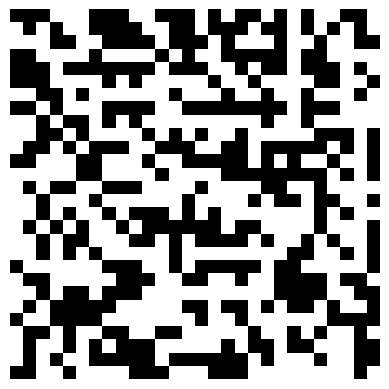

In [22]:
# Random initial visible configuration
v = torch.bernoulli(torch.full((N,), 0.5, device=device))

@torch.no_grad()
def Block_Gibbs_sampling(v, W, b_v, b_h, n):
    """Perform n Gibbs steps for one visible state or a batch of states."""
    for _ in range(n):
        # Sample hidden states conditioned on visible states.
        h = torch.bernoulli(hidden_probabilities(v, W, b_h))
        # Sample visible states conditioned on hidden states.
        v = torch.bernoulli(visible_probabilities(h, W, b_v))
    return v

v_sample = Block_Gibbs_sampling(v, W, a, b, 20)

plt.imshow(1 - v_sample.cpu().reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()


### Training the RBM on MNIST Dataset

We train the Bernoulli RBM using **Maximum Likelihood Estimation (MLE)**, approximating the negative phase with **Persistent Contrastive Divergence (PCD)** and updating parameters through Stochastic Gradient Ascent (SGA).

Recall the likelihood gradients:

$$
\begin{aligned}
\Delta_{W_{i\mu}}&=\langle v_ih_\mu\rangle_{\mathrm{data}}-\langle v_ih_\mu\rangle_{\mathrm{model}},\\
\Delta_{a_i}&=\langle v_i\rangle_{\mathrm{data}}-\langle v_i\rangle_{\mathrm{model}},\\
\Delta_{b_\mu}&=\langle h_\mu\rangle_{\mathrm{data}}-\langle h_\mu\rangle_{\mathrm{model}}.
\end{aligned}
$$

For each training iteration:

1. **Positive phase:** Select a minibatch of MNIST configurations, fix the visible units, and calculate the hidden conditional expectations.
2. **Negative phase (PCD):** Starting from persistent fantasy particles, perform a few block Gibbs iterations to approximate the model expectations.
3. **Parameter update:** Use the difference between positive and negative statistics to ascend the log-likelihood.

Collecting all parameters into $\boldsymbol\theta=\{\mathbf W,\mathbf a,\mathbf b\}$, the update rule is

$$
\boxed{
\boldsymbol\theta^{(t+1)}
=
\boldsymbol\theta^{(t)}
+
\epsilon\,\widehat{\nabla_{\boldsymbol\theta}\mathcal L}
}
$$

where $\epsilon$ is the learning rate and the gradient is estimated from the minibatch and fantasy particles.

**Why PCD?** Instead of restarting Gibbs chains from the training data at every update (ordinary CD), PCD continues sampling from the previous iteration's fantasy particles. This allows better exploration of the learned distribution, although short chains may still produce biased gradient estimates.

After training, the learned parameters define a generative Boltzmann distribution from which we can sample new MNIST-like images using Gibbs sampling.

In [23]:
def vh_data(v_set, W, b_h):
    """Data expectation <v_i h_mu>: [batch, N] -> [N, M]."""
    return (v_set.T @ hidden_probabilities(v_set, W, b_h)) / len(v_set)

def v_data(v_set, W, b_h):
    """Data expectation <v_i>: [batch, N] -> [N]."""
    return v_set.mean(dim=0)

def h_data(v_set, W, b_h):
    """Data expectation <h_mu>: [batch, N] -> [M]."""
    return hidden_probabilities(v_set, W, b_h).mean(dim=0)


In [24]:
@torch.no_grad()
def persistent_gibbs_sampling(v_set, W, b_v, b_h, n=20):
    """Advance persistent visible chains of shape [num_chains, N]."""
    samples = Block_Gibbs_sampling(v_set, W, b_v, b_h, n)
    # Draw hidden states conditioned on the final visible states.
    samples_h = torch.bernoulli(hidden_probabilities(samples, W, b_h))
    return samples, samples_h

def vh_model(samples, samples_h):
    """Model expectation <v_i h_mu>, averaged over persistent chains."""
    return (samples.T @ samples_h) / len(samples)

def v_model(samples):
    return samples.mean(dim=0)

def h_model(samples_h):
    return samples_h.mean(dim=0)


### Full Training Setup

1) We will divide data to random batches
2) Do SDA for all batches (1 epoch) and report losses
3) Continue till losses approach zero

In [25]:
batch_size = 128
num_epochs = 50
learning_rate0 = 0.01

train_batches = DataLoader(X_train, batch_size=batch_size, shuffle=True) # type: ignore
test_batches = DataLoader(X_test, batch_size=batch_size, shuffle=False) # type: ignore

# Initialize parameters again for training
N, M = 784, 256

W = 0.01 * torch.randn(N, M, device=device)
a = torch.zeros(N, device=device)
b = torch.zeros(M, device=device)

# Initialize persistent chains only once, outside both training loops.
samples = torch.bernoulli(
    torch.full((batch_size, N), 0.5, device=device)
)

history = []

with torch.no_grad():
    learning_rate = learning_rate0

    for epoch in range(num_epochs):
        total_errors = torch.zeros(3, device=device)
        num_examples = 0

        if epoch != 0 and epoch//10 == 0:
            # dynamically reduce learning rate every 10 epochs
            learning_rate *= 1.0

        for v_batch in train_batches:
            v_batch = v_batch.to(device)

            samples, samples_h = persistent_gibbs_sampling(samples, W, a, b, 100)

            err_W = vh_data(v_batch, W, b) - vh_model(samples, samples_h)
            err_a = v_data(v_batch, W, b) - v_model(samples)
            err_b = h_data(v_batch, W, b) - h_model(samples_h)

            W += learning_rate * err_W
            a += learning_rate * err_a
            b += learning_rate * err_b

            batch_n = len(v_batch)
            total_errors += batch_n * torch.stack([
                err_W.norm(), err_a.norm(), err_b.norm()
            ])
            num_examples += batch_n

        mean_errors = (total_errors / num_examples).cpu().tolist()
        history.append(mean_errors)

        print(
            f"Epoch {epoch + 1:3d}/{num_epochs} | "
            f"W update norm: {mean_errors[0]:.4f} | "
            f"a update norm: {mean_errors[1]:.4f} | "
            f"b update norm: {mean_errors[2]:.4f}"
        )

Epoch   1/50 | W update norm: 17.5060 | a update norm: 3.6692 | b update norm: 2.9255
Epoch   2/50 | W update norm: 29.9871 | a update norm: 2.7036 | b update norm: 2.5621
Epoch   3/50 | W update norm: 27.4174 | a update norm: 2.5748 | b update norm: 2.4202
Epoch   4/50 | W update norm: 23.7304 | a update norm: 2.2721 | b update norm: 2.0965
Epoch   5/50 | W update norm: 20.3696 | a update norm: 1.9681 | b update norm: 1.7701
Epoch   6/50 | W update norm: 18.4250 | a update norm: 1.7817 | b update norm: 1.5740
Epoch   7/50 | W update norm: 16.7132 | a update norm: 1.6164 | b update norm: 1.4005
Epoch   8/50 | W update norm: 15.7511 | a update norm: 1.5180 | b update norm: 1.3054
Epoch   9/50 | W update norm: 15.3217 | a update norm: 1.4808 | b update norm: 1.2570
Epoch  10/50 | W update norm: 14.5195 | a update norm: 1.3997 | b update norm: 1.1731
Epoch  11/50 | W update norm: 14.2570 | a update norm: 1.3736 | b update norm: 1.1525
Epoch  12/50 | W update norm: 14.2758 | a update norm:

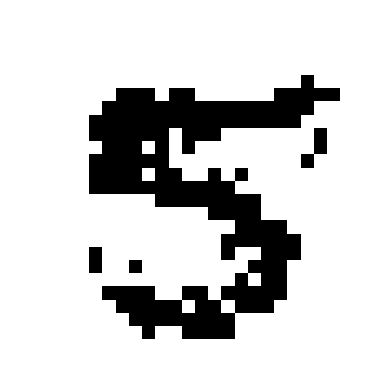

In [35]:
# Visualize a Sample
v0 = torch.bernoulli(torch.full((N,), 0.5, device=device))
v_sample1 = Block_Gibbs_sampling(v, W, a, b, 100)

plt.imshow(1 - v_sample1.cpu().reshape(28, 28), cmap="gray")
plt.axis("off")
plt.show()